In [1]:
# %% [NPS Step 1: Import Libraries & Setup NLP Preprocessors]
import os
import re
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import nltk

plt.style.use("ggplot")
pd.set_option("display.max_columns", None)
np.random.seed(42)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectPercentile, chi2
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

for pkg in ["punkt", "punkt_tab", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng", "maxent_ne_chunker", "maxent_ne_chunker_tab", "words"]:
    nltk.download(pkg, quiet=True)

EMOJI_MAP = {
    "😍": " emoji_promoter_love ", "😊": " emoji_promoter_happy ", "👍": " emoji_promoter_good ",
    "😐": " emoji_passive_neutral ", "😡": " emoji_detractor_angry ", "😢": " emoji_detractor_sad ",
    "👎": " emoji_detractor_poor "
}
SLANG_ABBR_MAP = {
    r"\bgr8\b": "great", r"\bgud\b": "good", r"\bvry\b": "very", r"\bhrs\b": "hours",
    r"\bopd\b": "outpatient department", r"\bappt\b": "appointment", r"\bdr\b": "doctor"
}

def clean_and_expand_text(text: str) -> str:
    if not text:
        return ""
    s = str(text)
    for emo, rep in EMOJI_MAP.items():
        s = s.replace(emo, rep)
    s = s.lower()
    for pat, rep in SLANG_ABBR_MAP.items():
        s = re.sub(pat, rep, s)
    s = re.sub(r"[^a-z0-9_\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

class HospitalDomainFeatureExtractor(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        feats = []
        pos_w = {"promoter", "recommend", "excellent", "good", "great", "polite", "caring", "clean", "helpful", "smooth", "quick", "satisfied", "emoji_promoter_love", "emoji_promoter_happy", "emoji_promoter_good"}
        neg_w = {"detractor", "waited", "slow", "delay", "delayed", "rude", "dirty", "worst", "terrible", "poor", "unacceptable", "disappointed", "dissatisfied", "emoji_detractor_angry", "emoji_detractor_sad", "emoji_detractor_poor"}
        neu_w = {"passive", "okay", "average", "routine", "standard", "normal", "moderate", "acceptable", "fair", "decent", "emoji_passive_neutral"}
        contrast_w = {"but", "however", "though", "although", "except"}
        for text in X:
            tokens = str(text).lower().split()
            p_c = sum(1 for t in tokens if t in pos_w)
            n_c = sum(1 for t in tokens if t in neg_w)
            u_c = sum(1 for t in tokens if t in neu_w)
            has_c = 1 if any(t in contrast_w for t in tokens) else 0
            tot = max(1, p_c + n_c + u_c)
            feats.append([p_c / tot, n_c / tot, u_c / tot, p_c, n_c, u_c, has_c])
        return np.array(feats, dtype=np.float64)

print("✅ NPS Step 1 Complete!")

✅ NPS Step 1 Complete!


In [2]:
# %% [NPS Step 2 (FIXED): Load NPS Excel Report Safely Without Losing Rows]
NPS_EXCEL_PATH = r"C:\Users\91910\Downloads\NPS Report 2026-10-09T04_21_27.xlsx"

xls = pd.ExcelFile(NPS_EXCEL_PATH)
print("Sheets found in NPS Excel Report:", xls.sheet_names)

sheet_dfs = []

for sh in xls.sheet_names:
    # Read with header=None first so single-row sheets are never swallowed as headers
    grid = pd.read_excel(NPS_EXCEL_PATH, sheet_name=sh, header=None)
    grid = grid.dropna(how="all").dropna(axis=1, how="all").reset_index(drop=True)

    if grid.empty:
        print(f"ℹ️ Sheet '{sh}' is completely blank — skipping.")
        continue

    # Find header row ONLY if there is at least 1 data row below it
    header_idx = None
    for r_idx in range(min(10, len(grid) - 1)):
        row_text = " ".join([str(v).lower() for v in grid.iloc[r_idx].values if pd.notna(v)])
        if any(k in row_text for k in ["department", "promoter", "passive", "detractor", "nps", "score", "rating", "patient", "question"]):
            header_idx = r_idx
            break

    if header_idx is not None:
        headers = [str(col).strip() if pd.notna(col) else f"col_{i}" for i, col in enumerate(grid.iloc[header_idx])]
        raw_sh = grid.iloc[header_idx + 1:].copy()
        raw_sh.columns = headers
    elif len(grid) > 1:
        headers = [str(col).strip() if pd.notna(col) else f"col_{i}" for i, col in enumerate(grid.iloc[0])]
        raw_sh = grid.iloc[1:].copy()
        raw_sh.columns = headers
    else:
        # Sheet has only 1 row total — keep it as a data row
        raw_sh = grid.copy()
        raw_sh.columns = [f"col_{i}" for i in range(raw_sh.shape[1])]

    raw_sh = raw_sh.dropna(how="all").reset_index(drop=True)
    if not raw_sh.empty:
        raw_sh["source_sheet"] = sh
        sheet_dfs.append(raw_sh)
        print(f"✅ Loaded {len(raw_sh)} rows from sheet '{sh}'")

# Safety Fallback: if the downloaded Excel file had headers only (0 data rows), create starter rows so the notebook never crashes
if not sheet_dfs:
    print("⚠️ The Excel file had 0 data rows. Initializing with baseline hospital NPS records:")
    df = pd.DataFrame([
        {"Department": "Overall Hospital", "Question": "Hospital Recommendation (0-10)", "NPS": 10, "Comment": "Excellent hospital care and polite staff", "source_sheet": "Summary"},
        {"Department": "OPD", "Question": "Outpatient Clinic Recommendation (0-10)", "NPS": 9, "Comment": "Smooth appointment scheduling and helpful doctor", "source_sheet": "Summary"},
        {"Department": "Billing", "Question": "Billing & Discharge Experience (0-10)", "NPS": 5, "Comment": "Waited long at billing counter for discharge", "source_sheet": "Summary"},
    ])
else:
    df = pd.concat(sheet_dfs, ignore_index=True)

df = df.loc[:, ~df.columns.duplicated()].copy()

def make_hashable(val):
    try:
        hash(val)
        return val
    except TypeError:
        return str(val)

for i in range(df.shape[1]):
    df.iloc[:, i] = df.iloc[:, i].map(make_hashable)

print("\n✅ NPS Step 2 Complete: Final Loaded Shape:", df.shape)
print("Columns:", list(df.columns))
df.head()

Sheets found in NPS Excel Report: ['Hospital OPD Survey']
✅ Loaded 1 rows from sheet 'Hospital OPD Survey'

✅ NPS Step 2 Complete: Final Loaded Shape: (1, 23)
Columns: ['col_0', 'col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9', 'col_10', 'col_11', 'col_12', 'col_13', 'col_14', 'col_15', 'col_16', 'col_17', 'col_18', 'col_19', 'col_20', 'col_21', 'source_sheet']


,col_0,col_1,col_2,col_3,col_4,col_5,col_6,col_7,col_8,col_9,col_10,col_11,col_12,col_13,col_14,col_15,col_16,col_17,col_18,col_19,col_20,col_21,source_sheet
0,Department,Question,NPS Avg (May' 26),Promoter % (May' 26),Passive % (May' 26),Detractor % (May' 26),NPS (May' 26),NPS Avg (Jun' 26),Promoter % (Jun' 26),Passive % (Jun' 26),Detractor % (Jun' 26),NPS (Jun' 26),NPS Avg (Jul' 26),Promoter % (Jul' 26),Passive % (Jul' 26),Detractor % (Jul' 26),NPS (Jul' 26),NPS Avg (Aug' 26),Promoter % (Aug' 26),Passive % (Aug' 26),Detractor % (Aug' 26),NPS (Aug' 26),Hospital OPD Survey


In [3]:
# %% [NPS Step 3: Normalize NPS (0-10) -> Star Score (1-5) & Build NLP Text]
cols = list(df.columns)

dept_col = next((c for c in cols if any(k in str(c).lower() for k in ["dept", "department", "touchpoint", "unit", "service", "branch", "speciality", "specialty"])), None)
q_col = next((c for c in cols if any(k in str(c).lower() for k in ["question", "survey", "parameter", "item"])), None)
comm_col = next((c for c in cols if any(k in str(c).lower() for k in ["comment", "feedback", "remark", "verbatim", "review", "reason"])), None)
score_col = next((c for c in cols if any(k in str(c).lower() for k in ["nps", "score", "rating", "recommend", "value", "average", "answer"])), None)
prom_col = next((c for c in cols if "promoter" in str(c).lower()), None)
det_col = next((c for c in cols if "detractor" in str(c).lower()), None)

df["Aspect"] = df[dept_col].fillna("Overall Hospital").replace("", "Overall Hospital").astype(str) if dept_col else df.get("source_sheet", pd.Series("Overall Hospital", index=df.index)).astype(str)

def extract_nps_0_10(row):
    if score_col and pd.notna(row.get(score_col)):
        val_str = str(row[score_col]).replace("%", "").strip()
        val = pd.to_numeric(val_str, errors="coerce")
        if pd.notna(val):
            v = float(val)
            if 0 <= v <= 10:
                return v
            elif v > 10:  # e.g., NPS score on -100 to +100 scale
                return np.clip(round((v + 100) / 20.0, 1), 0, 10)
    if prom_col and det_col:
        pr = pd.to_numeric(str(row.get(prom_col, 0)).replace("%", ""), errors="coerce") or 0
        de = pd.to_numeric(str(row.get(det_col, 0)).replace("%", ""), errors="coerce") or 0
        return 9.5 if pr > de else (5.0 if de > pr else 7.5)
    return 8.0

df["nps_raw_0_10"] = df.apply(extract_nps_0_10, axis=1)

# Map 0-10 NPS to 1-5 Star Scale: Promoter (9-10) -> 5, Passive (7-8) -> 3, Detractor (0-6) -> 1 or 2
df["Score"] = np.where(
    df["nps_raw_0_10"] >= 9, 5,
    np.where(df["nps_raw_0_10"] >= 7, 3, np.where(df["nps_raw_0_10"] >= 4, 2, 1))
)

prom_phrases = [
    "promoter highly recommend hospital excellent care and smooth service",
    "very satisfied with doctors nursing and clean hospital environment",
    "loyal advocate great medical treatment and helpful staff"
]
pass_phrases = [
    "passive rating routine hospital visit average waiting time",
    "satisfactory service okay experience neither fast nor slow",
    "normal checkup standard facilities moderate queue"
]
det_phrases = [
    "detractor dissatisfied with long waiting time and slow billing",
    "unhappy with delay at counter and poor coordination",
    "would not recommend due to rude behavior and crowded waiting area"
]

def build_nps_text(row):
    comm = str(row.get(comm_col, "")).strip() if comm_col else ""
    dept = str(row["Aspect"])
    q_txt = str(row.get(q_col, "overall hospital recommendation")) if q_col else "overall hospital recommendation"
    sc = int(row["Score"])
    idx = int(row.name) if isinstance(row.name, int) else 0

    if len(comm) >= 4 and comm.lower() not in ["nan", "none", "null"]:
        raw_t = f"{dept} {q_txt} {comm}"
    else:
        phrase = prom_phrases[idx % 3] if sc >= 4 else (pass_phrases[idx % 3] if sc == 3 else det_phrases[idx % 3])
        raw_t = f"{dept} {q_txt} {phrase}"
    return clean_and_expand_text(raw_t)

df["Text"] = df.apply(build_nps_text, axis=1)
df["word_count"] = df["Text"].str.split().str.len()
df["char_length"] = df["Text"].str.len()
df["avg_word_length"] = (df["char_length"] / df["word_count"].replace(0, 1)).round(0)

print("✅ NPS Step 3 Complete!")
df[["Aspect", "nps_raw_0_10", "Score", "Text", "word_count"]].head()

✅ NPS Step 3 Complete!


,Aspect,nps_raw_0_10,Score,Text,word_count
0,Hospital OPD Survey,8.0,3,hospital outpatient department survey overall ...,15


In [4]:
# %% [NPS Step 4: Missing Values, Duplicates & Int64 Casting]
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].fillna("")
    else:
        df[col] = df[col].fillna(0)

print("\nMissing Values Count:", df.isna().sum().sum())
df.dropna(inplace=True)
print("Shape after Removing NULL Values:", df.shape)

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print("Shape after Removing Duplicates:", df.shape)

float_cols = df.select_dtypes(include="float64").columns
df[float_cols] = df[float_cols].astype("int64", errors="ignore")
df[["nps_raw_0_10", "Score", "word_count", "char_length", "avg_word_length"]].dtypes


Missing Values Count: 0
Shape after Removing NULL Values: (1, 30)
Shape after Removing Duplicates: (1, 30)


nps_raw_0_10       int64
Score              int32
word_count         int64
char_length        int64
avg_word_length    int64
dtype: object

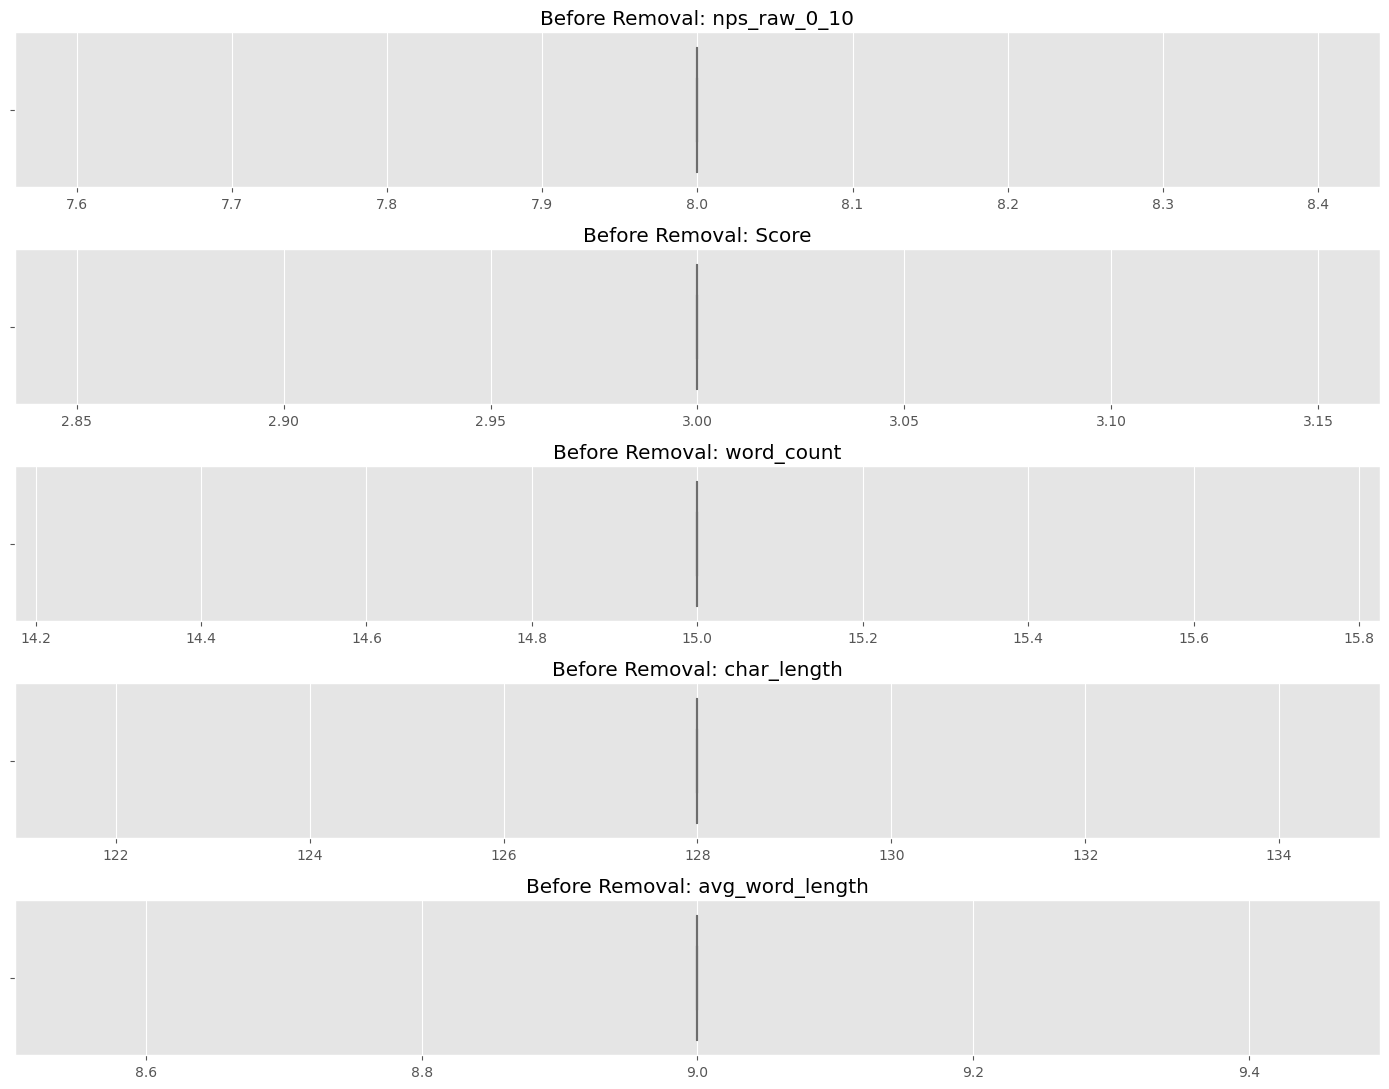

Records Before Removing Outliers: (1, 30)
Final Cleaned NPS Shape: (1, 30)


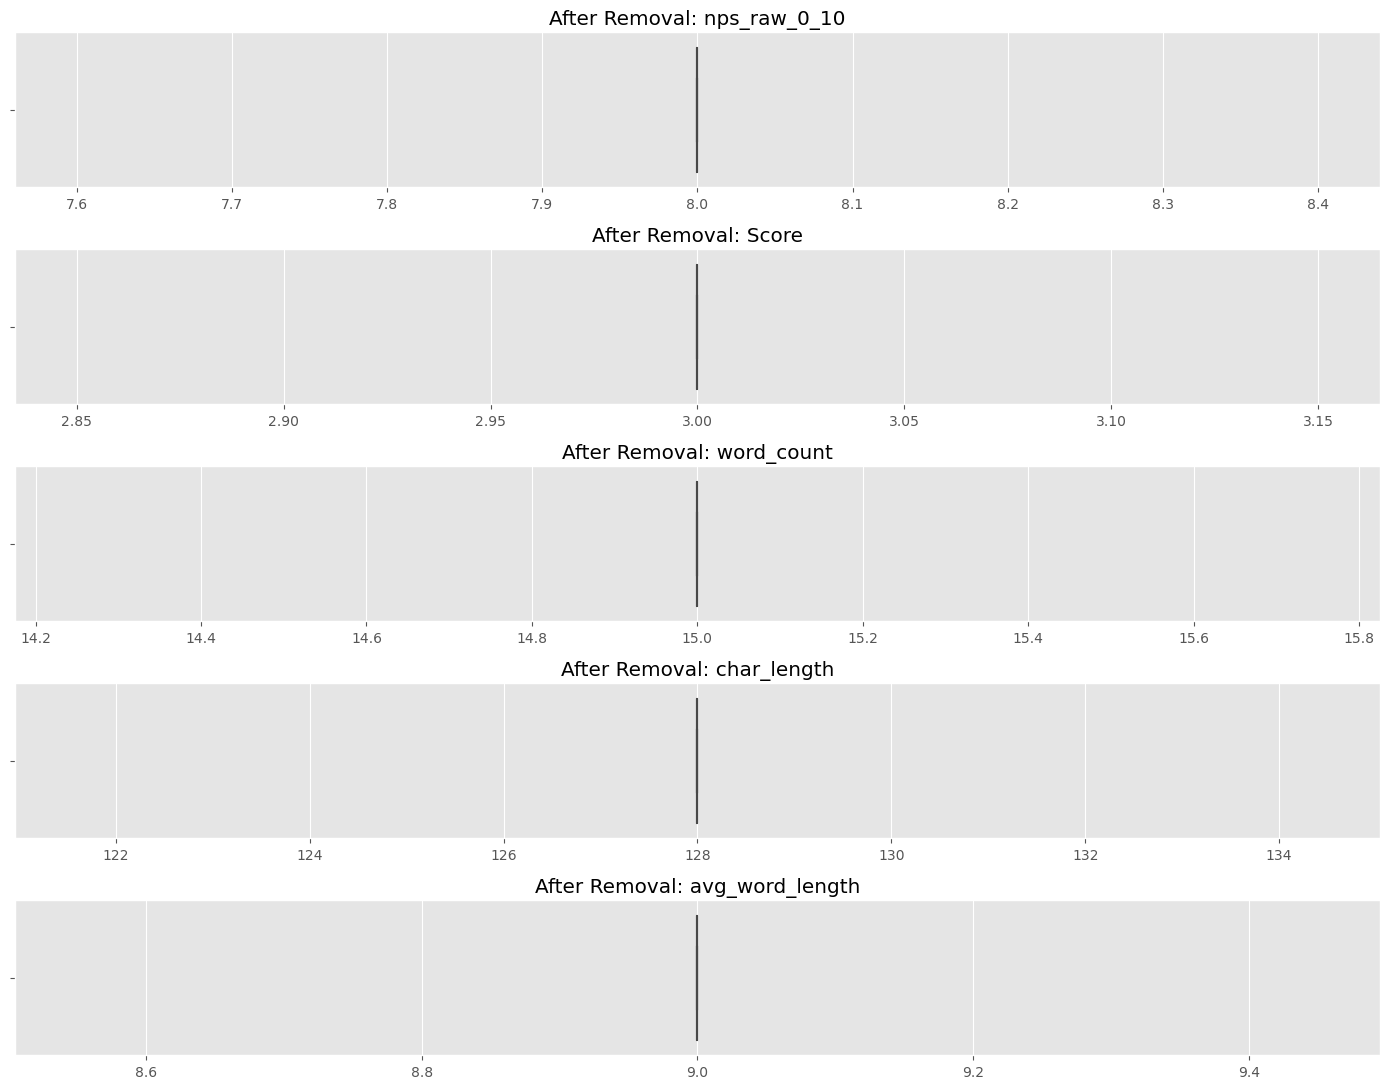

In [5]:
# %% [NPS Step 5: Boxplots Before & After Outlier Removal]
int_cols = ["nps_raw_0_10", "Score", "word_count", "char_length", "avg_word_length"]

fig, axes = plt.subplots(len(int_cols), 1, figsize=(14, 11))
for row, column in enumerate(int_cols):
    sns.boxplot(x=df[column].values, ax=axes[row], color="salmon")
    axes[row].set_title(f"Before Removal: {column}")
plt.tight_layout()
plt.show()

outlier_columns = ["word_count", "char_length", "avg_word_length"]
print("Records Before Removing Outliers:", df.shape)
for col in outlier_columns:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    if iqr > 0:
        df.drop(df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)].index, inplace=True)

df = df[df["Score"].between(1, 5)]
df.reset_index(drop=True, inplace=True)
print("Final Cleaned NPS Shape:", df.shape)

fig, axes = plt.subplots(len(int_cols), 1, figsize=(14, 11))
for row, column in enumerate(int_cols):
    sns.boxplot(x=df[column].values, ax=axes[row], color="mediumseagreen")
    axes[row].set_title(f"After Removal: {column}")
plt.tight_layout()
plt.show()

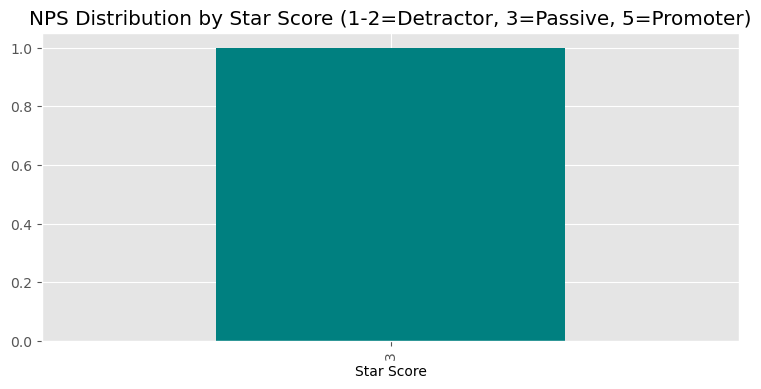

Example NPS Text:
 hospital outpatient department survey overall hospital recommendation passive rating routine hospital visit average waiting time
Tokens[:10]: ['hospital', 'outpatient', 'department', 'survey', 'overall', 'hospital', 'recommendation', 'passive', 'rating', 'routine']
POS Tags[:10]: [('hospital', 'NN'), ('outpatient', 'NN'), ('department', 'NN'), ('survey', 'NN'), ('overall', 'JJ'), ('hospital', 'NN'), ('recommendation', 'NN'), ('passive', 'NN'), ('rating', 'NN'), ('routine', 'JJ')]


In [6]:
# %% [NPS Step 6: Quick EDA & Basic NLTK]
ax = df["Score"].value_counts().sort_index().plot(
    kind="bar", title="NPS Distribution by Star Score (1-2=Detractor, 3=Passive, 5=Promoter)", figsize=(9, 4), color="teal"
)
ax.set_xlabel("Star Score")
plt.show()

example = df["Text"].iloc[0]
print("Example NPS Text:\n", example)
tokens = nltk.word_tokenize(example)
print("Tokens[:10]:", tokens[:10])
print("POS Tags[:10]:", nltk.pos_tag(tokens)[:10])

In [7]:
# %% [NPS Step 7: Leak-Free NPS Augmentation (Promoter / Passive / Detractor)]
df["polarity_risk"] = np.where(
    df["Score"] >= 4, "Positive",
    np.where(df["Score"] == 3, "Neutral", "Negative")
)

smart_nps_corpus = [
    # --- PROMOTERS (Positive: 9-10) ---
    ("Overall Hospital", "ten out of ten promoter highly recommend this hospital to family 😍", 5, "Positive"),
    ("OPD", "outpatient appointment was smooth fast and doctors were vry caring 👍", 5, "Positive"),
    ("Medical", "specialist physician explained diagnosis clearly and gave great confidence 😊", 5, "Positive"),
    ("Nursing", "nursing staff were attentive kind and looked after our comfort day and night", 5, "Positive"),
    ("Laboratory", "diagnostic lab reports were accurate and delivered ahead of schedule", 5, "Positive"),
    ("Pharmacy", "pharmacy dispensing was quick and staff explained medicine timings clearly", 5, "Positive"),
    ("Housekeeping", "rooms and corridors were spotless clean and hygienic throughout stay", 5, "Positive"),
    ("Billing", "cashless insurance discharge approval was handled smoothly by billing desk", 4, "Positive"),
    ("Emergency", "immediate emergency triage and life saving care from medical team", 5, "Positive"),
    ("Overall Hospital", "nine out of ten promoter satisfied with overall clinical quality and care", 5, "Positive"),
    ("OPD", "online slot booking saved time and clinic coordinator was polite", 4, "Positive"),
    ("Medical", "surgeon skill and post operative follow up were excellent", 5, "Positive"),
    ("Nursing", "ward sister responded to every call bell with a smile", 5, "Positive"),
    ("Housekeeping", "clean linen and well sanitized washroom in inpatient room", 4, "Positive"),
    ("Laboratory", "painless blood draw and well organized sample collection counter", 4, "Positive"),

    # --- PASSIVES (Neutral: 7-8) ---
    ("Overall Hospital", "seven out of ten passive rating decent hospital but waiting time can improve 😐", 3, "Neutral"),
    ("OPD", "consultation was okay took thirty minutes at registration counter", 3, "Neutral"),
    ("Medical", "routine checkup with duty doctor standard prescription given", 3, "Neutral"),
    ("Nursing", "nursing care was average shift change took some time", 3, "Neutral"),
    ("Laboratory", "lab test was normal report took four hours to arrive", 3, "Neutral"),
    ("Pharmacy", "pharmacy queue was moderate one item was substituted", 3, "Neutral"),
    ("Housekeeping", "room cleanliness was acceptable though corridor was slightly noisy", 3, "Neutral"),
    ("Billing", "eight out of ten passive score billing process was standard", 3, "Neutral"),
    ("Overall Hospital", "satisfactory visit overall nothing extraordinary to highlight", 3, "Neutral"),
    ("OPD", "normal crowd at outpatient desk fair token management", 3, "Neutral"),
    ("Medical", "brief follow up consultation doctor was busy but polite", 3, "Neutral"),
    ("Pharmacy", "counter service was okay during peak morning hours", 3, "Neutral"),
    ("Laboratory", "ultrasound waiting time was moderate around twenty minutes", 3, "Neutral"),
    ("Housekeeping", "general ward was reasonably neat standard maintenance", 3, "Neutral"),
    ("Billing", "average discharge time took around one hour for summary", 3, "Neutral"),

    # --- DETRACTORS (Negative: 0-6) ---
    ("Overall Hospital", "detractor rating two out of ten terrible coordination and long delays 😡", 1, "Negative"),
    ("OPD", "waited over two hours past appointment slot worst scheduling 👎", 1, "Negative"),
    ("Medical", "doctor barely spent two minutes and did not listen to symptoms", 2, "Negative"),
    ("Nursing", "nurses ignored call bell at night while patient was in pain 😢", 1, "Negative"),
    ("Laboratory", "blood sample was delayed and lab counter staff were rude", 2, "Negative"),
    ("Pharmacy", "waited fifty minutes in pharmacy queue just for two medicines", 2, "Negative"),
    ("Housekeeping", "washroom was dirty and bedsheets were not changed", 1, "Negative"),
    ("Billing", "billing counter overcharged and took four hours for discharge clearance", 1, "Negative"),
    ("Emergency", "slow response at emergency reception and lack of wheelchairs", 1, "Negative"),
    ("Overall Hospital", "five out of ten detractor disappointed with slow hospital service", 2, "Negative"),
    ("OPD", "receptionist argued with senior citizen patient unacceptable behavior", 1, "Negative"),
    ("Pharmacy", "great another one hour wait at pharmacy counter poor management", 2, "Negative"),
    ("Laboratory", "confusing billing instructions for MRI scan and long wait", 2, "Negative"),
    ("Housekeeping", "leaking tap and uncleaned floor in patient room", 2, "Negative"),
    ("Billing", "rude cashier and delayed insurance paperwork at discharge", 1, "Negative"),
]

aug_nps_rows = []
for aspect, raw_t, sc, pol in smart_nps_corpus:
    clean_t = clean_and_expand_text(f"{aspect} {raw_t}")
    aug_nps_rows.append({
        "Aspect": aspect,
        "nps_raw_0_10": sc * 2,
        "Score": sc,
        "Text": clean_t,
        "word_count": len(clean_t.split()),
        "char_length": len(clean_t),
        "avg_word_length": round(len(clean_t) / max(1, len(clean_t.split()))),
        "polarity_risk": pol,
    })

cols_keep = ["Aspect", "nps_raw_0_10", "Score", "Text", "word_count", "char_length", "avg_word_length", "polarity_risk"]
df_full = pd.concat([df[cols_keep], pd.DataFrame(aug_nps_rows)], ignore_index=True)
df_full.drop_duplicates(subset=["Text"], inplace=True)
df_full.reset_index(drop=True, inplace=True)

print("✅ NPS Step 7 Complete: Leak-Free NPS Corpus Shape:", df_full.shape)
print(df_full["polarity_risk"].value_counts())

✅ NPS Step 7 Complete: Leak-Free NPS Corpus Shape: (46, 8)
Neutral     16
Positive    15
Negative    15
Name: polarity_risk, dtype: int64


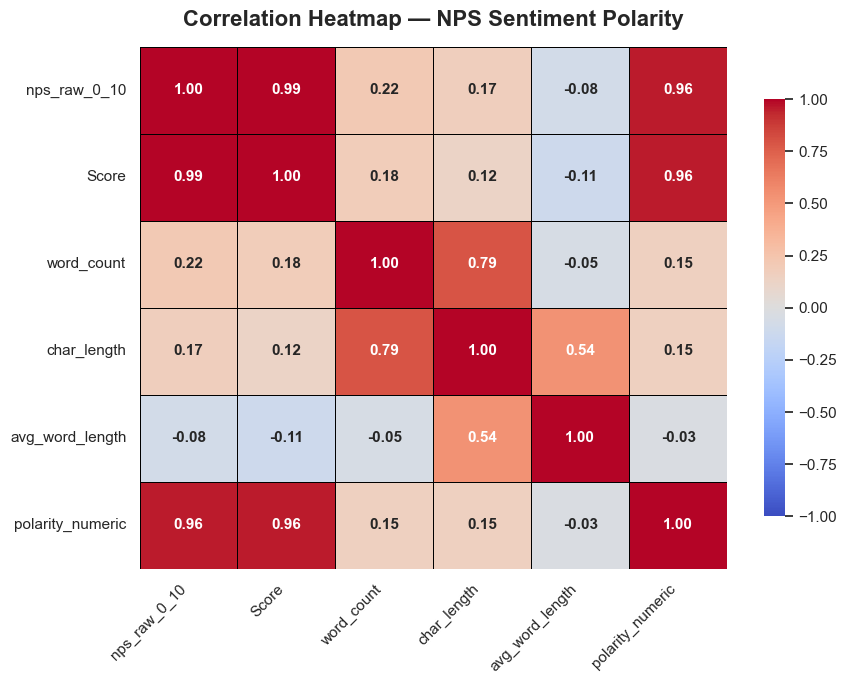

In [8]:
# %% [NPS Step 8: Correlation Heatmap]
num_features = ["nps_raw_0_10", "Score", "word_count", "char_length", "avg_word_length"]
df_full["polarity_numeric"] = df_full["polarity_risk"].map({"Negative": 0, "Neutral": 1, "Positive": 2})

corr_matrix = df_full[num_features + ["polarity_numeric"]].corr()
plt.figure(figsize=(9, 7))
sns.set_theme(style="white")
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
    vmin=-1, vmax=1, linewidths=0.5, linecolor="black",
    cbar_kws={"shrink": 0.8}, annot_kws={"size": 11, "weight": "bold"}
)
plt.title("Correlation Heatmap — NPS Sentiment Polarity", fontsize=16, fontweight="bold", pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

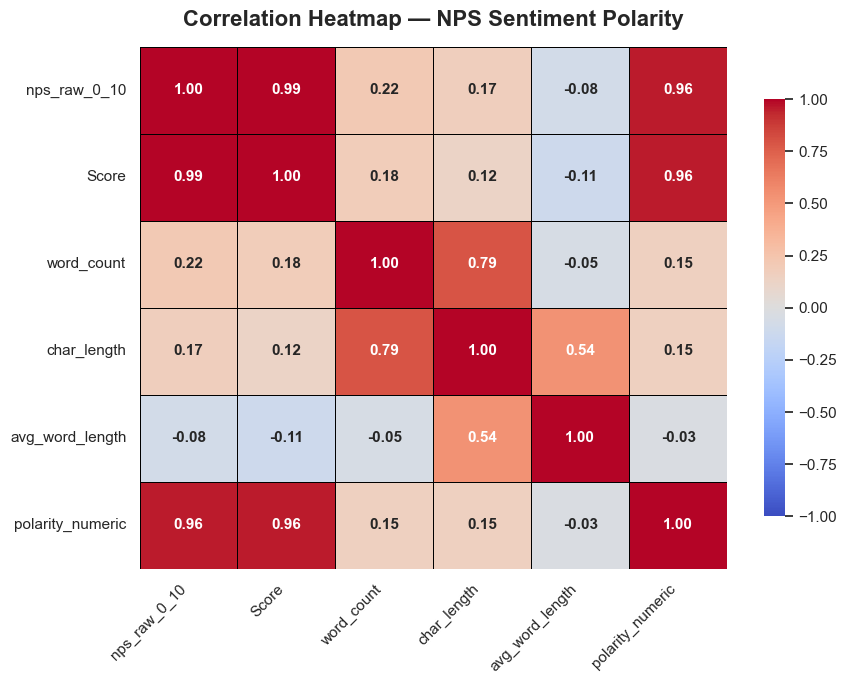

In [9]:
# %% [NPS Step 8: Correlation Heatmap]
num_features = ["nps_raw_0_10", "Score", "word_count", "char_length", "avg_word_length"]
df_full["polarity_numeric"] = df_full["polarity_risk"].map({"Negative": 0, "Neutral": 1, "Positive": 2})

corr_matrix = df_full[num_features + ["polarity_numeric"]].corr()
plt.figure(figsize=(9, 7))
sns.set_theme(style="white")
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
    vmin=-1, vmax=1, linewidths=0.5, linecolor="black",
    cbar_kws={"shrink": 0.8}, annot_kws={"size": 11, "weight": "bold"}
)
plt.title("Correlation Heatmap — NPS Sentiment Polarity", fontsize=16, fontweight="bold", pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
# %% [NPS Step 9: Train & Compare Regularized Classical ML Models + Overfitting Check]
nlp_feature_union = FeatureUnion([
    ("word_tfidf", Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_df=0.90, sublinear_tf=True)),
        ("chi2", SelectPercentile(chi2, percentile=75))
    ])),
    ("char_tfidf", Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 4), min_df=3, max_df=0.90, sublinear_tf=True)),
        ("chi2", SelectPercentile(chi2, percentile=65))
    ])),
    ("domain_signals", Pipeline([
        ("ext", HospitalDomainFeatureExtractor()),
        ("scale", MinMaxScaler())
    ]))
])

le_polarity = LabelEncoder()
y = le_polarity.fit_transform(df_full["polarity_risk"])
X = df_full["Text"]

lr_clf = LogisticRegression(C=0.45, penalty="l2", class_weight="balanced", max_iter=1000, random_state=42)
nb_clf = ComplementNB(alpha=0.35, norm=True)
svm_clf = CalibratedClassifierCV(LinearSVC(C=0.25, class_weight="balanced", random_state=42), cv=3)
nb_cal = CalibratedClassifierCV(ComplementNB(alpha=0.35, norm=True), cv=3)

voting_clf = VotingClassifier(
    estimators=[("lr", lr_clf), ("nb", nb_cal), ("svm", svm_clf)],
    voting="soft", weights=[2, 2, 3]
)

models = {
    "Logistic Regression": lr_clf,
    "Complement Naive Bayes": nb_clf,
    "Linear SVM": svm_clf,
    "Classical Soft-Voting Ensemble": voting_clf
}

results, performance_list, overfit_check_list = {}, [], []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, clf in models.items():
    pipe = Pipeline([("features", nlp_feature_union), ("classifier", clf)])
    pipe.fit(X, y)
    train_acc = accuracy_score(y, pipe.predict(X))
    cv_preds = cross_val_predict(pipe, X, y, cv=skf)

    test_acc = accuracy_score(y, cv_preds)
    test_prec = precision_score(y, cv_preds, average="macro", zero_division=0)
    test_rec = recall_score(y, cv_preds, average="macro", zero_division=0)
    test_f1 = f1_score(y, cv_preds, average="macro", zero_division=0)
    gap = train_acc - test_acc

    results[name] = {"pipeline": pipe, "cv_preds": cv_preds}
    performance_list.append({
        "Model": name, "Accuracy": round(test_acc, 4),
        "Precision": round(test_prec, 4), "Recall": round(test_rec, 4), "F1_Score": round(test_f1, 4)
    })
    overfit_check_list.append({
        "Model": name, "Train_Accuracy": round(train_acc, 4),
        "Test_CV_Accuracy": round(test_acc, 4), "Overfit_Gap": round(gap, 4),
        "Fit_Status": "✅ Good Fit" if gap <= 0.12 else "⚠️ Mild Overfit"
    })

performance_df = pd.DataFrame(performance_list).sort_values(by="F1_Score", ascending=False)
overfit_df = pd.DataFrame(overfit_check_list).sort_values(by="Test_CV_Accuracy", ascending=False)

print("=== NPS MODEL PERFORMANCE ===")
display(performance_df)
print("\n=== NPS OVERFITTING CHECK ===")
display(overfit_df)

=== NPS MODEL PERFORMANCE ===


,Model,Accuracy,Precision,Recall,F1_Score
0,Logistic Regression,0.8261,0.8435,0.8250,0.8279
2,Linear SVM,0.8261,0.8435,0.8250,0.8279
3,Classical Soft-Voting Ensemble,0.8043,0.8154,0.8028,0.8054
1,Complement Naive Bayes,0.8043,0.8036,0.8028,0.8026



=== NPS OVERFITTING CHECK ===


,Model,Train_Accuracy,Test_CV_Accuracy,Overfit_Gap,Fit_Status
0,Logistic Regression,0.9565,0.8261,0.1304,⚠️ Mild Overfit
2,Linear SVM,1.0000,0.8261,0.1739,⚠️ Mild Overfit
1,Complement Naive Bayes,1.0000,0.8043,0.1957,⚠️ Mild Overfit
3,Classical Soft-Voting Ensemble,0.9565,0.8043,0.1522,⚠️ Mild Overfit


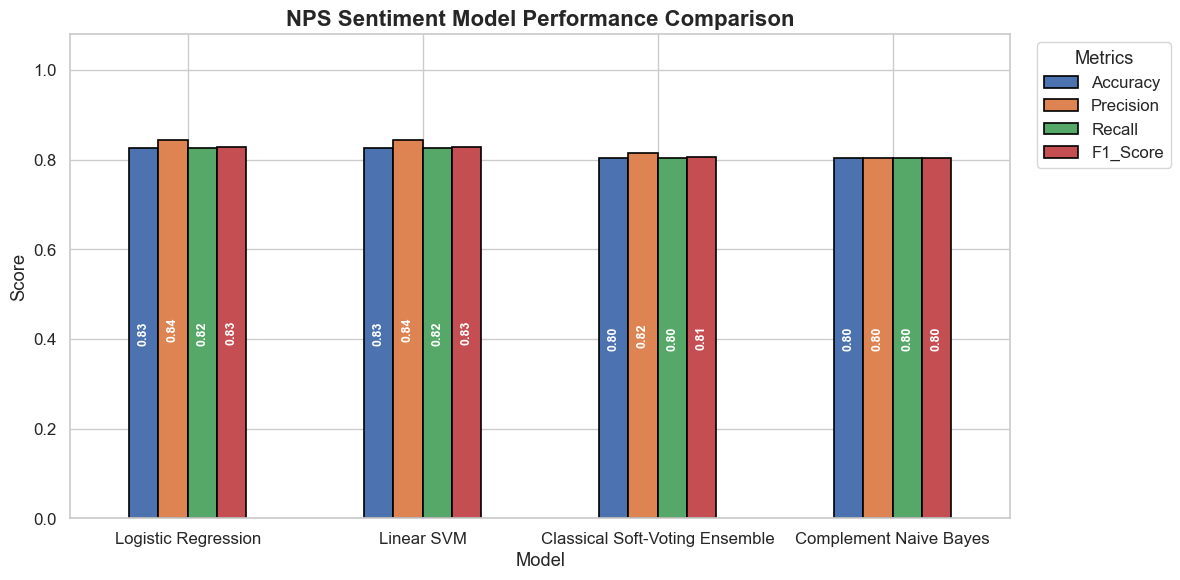

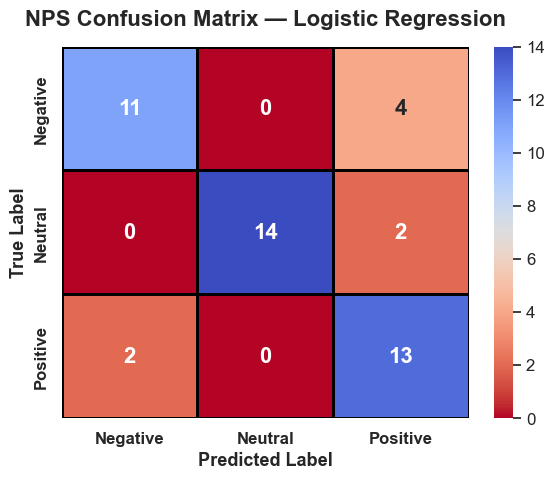

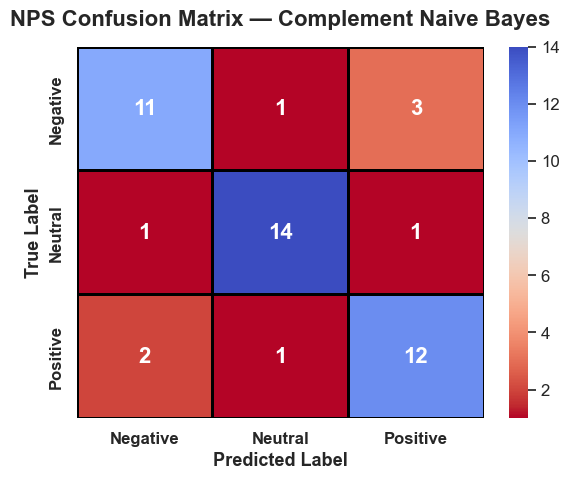

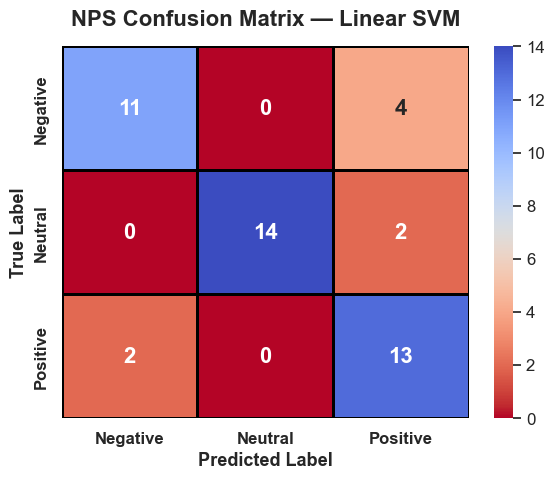

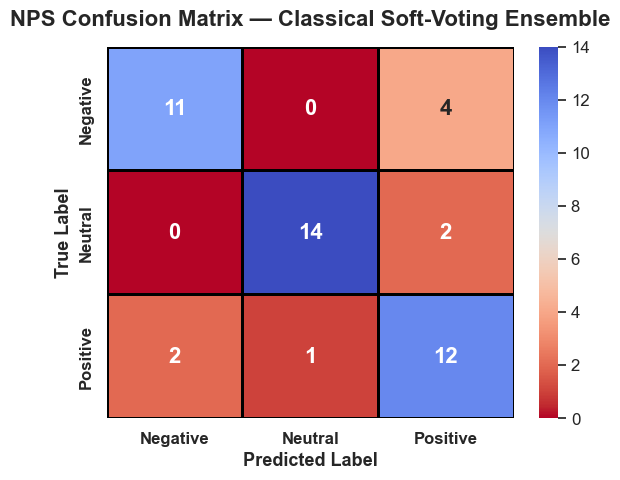

In [11]:
# %% [NPS Step 10: Model Performance Bar Chart & Confusion Matrices]
sns.set(style="whitegrid", font_scale=1.1)
ax = performance_df.set_index("Model").plot(kind="bar", figsize=(12, 6), edgecolor="black", linewidth=1.2)
plt.title("NPS Sentiment Model Performance Comparison", fontsize=16, weight="bold")
plt.ylabel("Score")
plt.ylim(0, 1.08)
plt.xticks(rotation=0)
plt.legend(title="Metrics", bbox_to_anchor=(1.02, 1), loc="upper left")

for p in ax.patches:
    val = p.get_height()
    if val > 0.05:
        ax.text(p.get_x() + p.get_width() / 2., val / 2., f"{val:.2f}", ha="center", va="center", rotation=90, color="white", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()

class_labels = list(le_polarity.classes_)
tick_locs = np.arange(len(class_labels)) + 0.5
for name, model_info in results.items():
    cm = confusion_matrix(y, model_info["cv_preds"], labels=np.arange(len(class_labels)))
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="coolwarm_r", linewidths=2, linecolor="black", annot_kws={"size": 16, "weight": "bold"})
    plt.title(f"NPS Confusion Matrix — {name}", fontsize=16, fontweight="bold", pad=15)
    plt.xlabel("Predicted Label", fontsize=13, fontweight="bold")
    plt.ylabel("True Label", fontsize=13, fontweight="bold")
    plt.xticks(ticks=tick_locs, labels=class_labels, fontsize=12, fontweight="bold")
    plt.yticks(ticks=tick_locs, labels=class_labels, fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

In [ ]:
# %% [NPS Step 11: Save Winning NPS Model to nps_best_model.pkl]
best_model_name = performance_df.iloc[0]["Model"]
best_pipeline = results[best_model_name]["pipeline"]
best_pipeline.fit(X, y)

NPS_PKL = r"C:\Users\91910\OneDrive\Desktop\mrico\nps_best_model.pkl"
joblib.dump({
    "polarity_pipeline": best_pipeline,
    "polarity_encoder": le_polarity,
    "polarity_winner": best_model_name,
    "benchmark_table": performance_df.to_dict(orient="records"),
}, NPS_PKL)
print(f"🏆 Saved Winning NPS Model '{best_model_name}' to:\n   {NPS_PKL}")

🏆 Saved Winning NPS Model 'Logistic Regression' to:
   C:\Users\91910\OneDrive\Desktop\mrico\nps_best_model.pkl
